<a href="https://colab.research.google.com/github/pradyumn980/EV-Battery-Anomaly-Detection/blob/main/EV_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

# GitHub raw dataset URL
url = "https://raw.githubusercontent.com/pradyumn980/EV-Battery-Anomaly-Detection/refs/heads/main/ev_battery_health.csv"

# Load dataset
df = pd.read_csv(url)

# Display dataset
display(df.head())

# Dataset information
df.info()

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   battery_id                      50000 non-null  object 
 1   observation_id                  50000 non-null  object 
 2   chemistry                       46541 non-null  object 
 3   manufacturer                    47539 non-null  object 
 4   vehicle_model                   46485 non-null  object 
 5   pack_capacity_kwh               47698 non-null  float64
 6   manufacture_date                48090 non-null  object 
 7   observation_date                47784 non-null  object 
 8   battery_age_days                46998 non-null  float64
 9   cycle_count                     47731 non-null  float64
 10  climate_zone                    47281 non-null  object 
 11  avg_daily_distance_km           47882 non-null  float64
 12  avg_charging_power_kw           

In [3]:
data = df.copy()

print("Original shape:", data.shape)

Original shape: (50000, 35)


In [4]:
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 0


In [5]:
missing = data.isnull().sum()

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing Percentage': (missing / len(data)) * 100
})

display(missing_df[missing_df['Missing Count'] > 0]
        .sort_values('Missing Percentage', ascending=False))

,Missing Count,Missing Percentage
last_service_date,18831,37.662
vehicle_model,3515,7.030
chemistry,3459,6.918
fast_charge_ratio,3405,6.810
total_energy_throughput_kwh,3370,6.740
avg_ambient_temp_c,3282,6.564
avg_state_of_charge_pct,3138,6.276
battery_age_days,3002,6.004
avg_depth_of_discharge_pct,2832,5.664
voltage_avg_v,2807,5.614


In [6]:
sensor_features = [
    'internal_resistance_mohm',
    'peak_temp_during_fast_charge_c',
    'charge_time_avg_min'
]

sensor_data = data[sensor_features].copy()

display(sensor_data.head())
print(sensor_data.isnull().sum())

,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
0,92.70,-1.3,40.1
1,49.95,5.3,38.0
2,37.90,21.3,41.7
3,NaN,20.8,18.2
4,68.34,40.1,79.2


internal_resistance_mohm          2104
peak_temp_during_fast_charge_c    2128
charge_time_avg_min               2091
dtype: int64


# **Data preprocessing**

In [7]:
sensor_data = sensor_data.dropna(
    subset=sensor_features,
    how='all'
)

print("Shape:", sensor_data.shape)

Shape: (49997, 3)


In [8]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_imputed = pd.DataFrame(
    imputer.fit_transform(sensor_data),
    columns=sensor_features,
    index=sensor_data.index
)

print("Missing values after imputation:")
print(X_imputed.isnull().sum())

Missing values after imputation:
internal_resistance_mohm          0
peak_temp_during_fast_charge_c    0
charge_time_avg_min               0
dtype: int64


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

processed_data = pd.DataFrame(
    X_scaled,
    columns=sensor_features,
    index=X_imputed.index
)

display(processed_data.head())

,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
0,2.093732,-2.210485,-0.793360
1,0.047776,-1.688228,-0.813032
2,-0.528921,-0.422149,-0.778373
3,-0.281013,-0.461714,-0.998507
4,0.927896,1.065492,-0.427094


In [10]:
print("Dataset shape:", processed_data.shape)

print("\nMissing values:")
print(processed_data.isnull().sum())

print("\nStatistical summary:")
display(processed_data.describe())

Dataset shape: (49997, 3)

Missing values:
internal_resistance_mohm          0
peak_temp_during_fast_charge_c    0
charge_time_avg_min               0
dtype: int64

Statistical summary:


,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
count,4.999700e+04,4.999700e+04,4.999700e+04
mean,1.350112e-16,1.624398e-16,1.259157e-16
std,1.000010e+00,1.000010e+00,1.000010e+00
min,-1.975373e+00,-2.970439e+00,-1.117745e+00
25%,-6.595751e-01,-6.595391e-01,-5.854036e-01
50%,-2.810132e-01,1.306485e-02,-2.847092e-01
75%,3.425848e-01,6.698428e-01,2.061439e-01
max,1.235417e+01,5.302114e+00,1.037570e+01


# **Exploratory Data Analysis (EDA)**

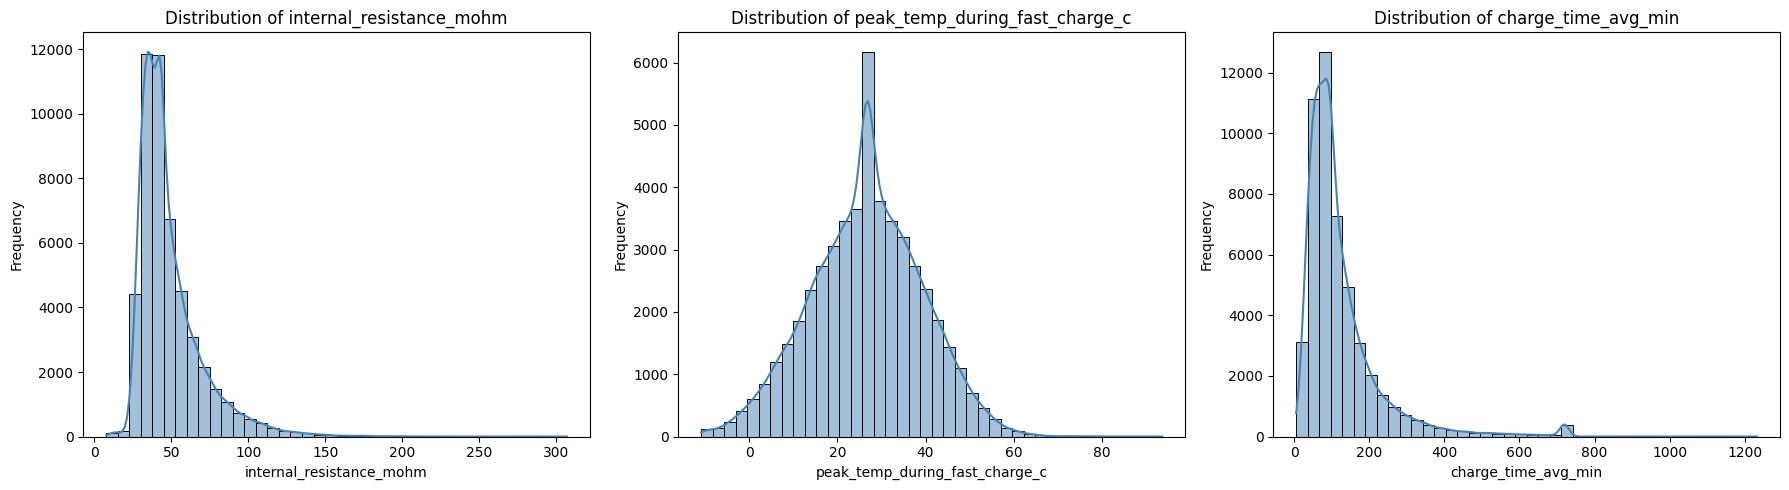

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(sensor_features):
    sns.histplot(
        X_imputed[col],
        bins=40,
        kde=True,
        ax=axes[i],
        color='steelblue'
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

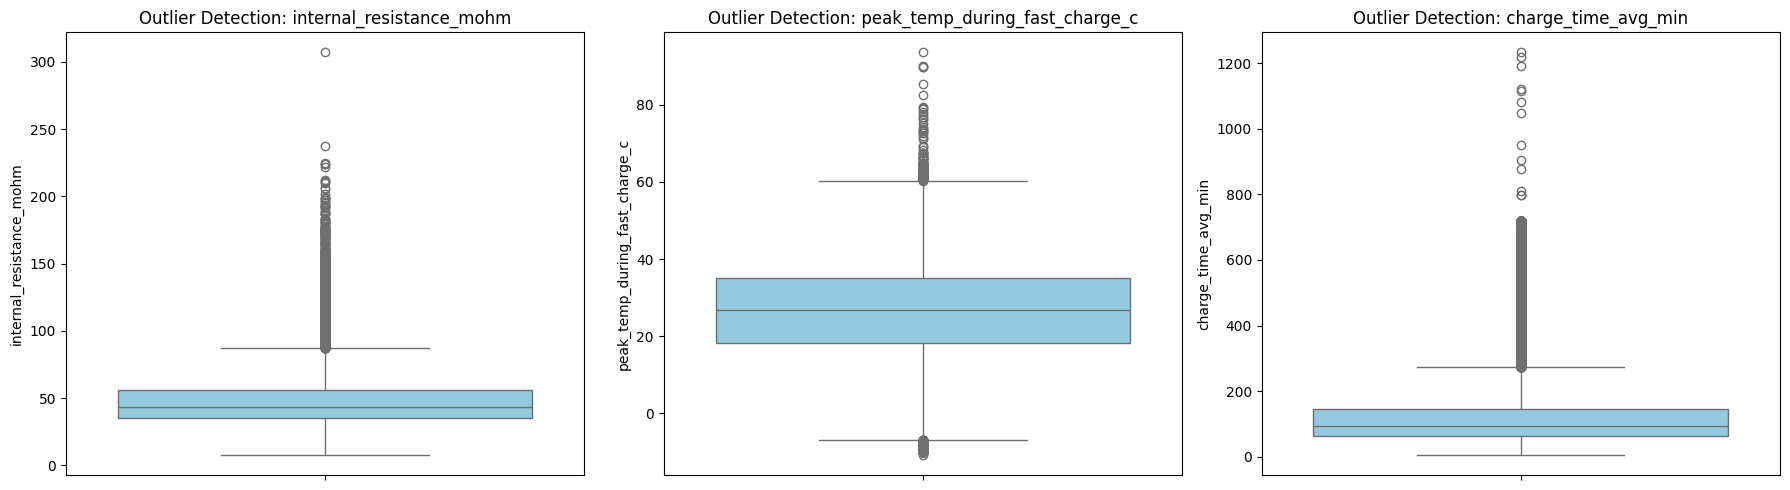

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(sensor_features):
    sns.boxplot(
        y=X_imputed[col],
        ax=axes[i],
        color='skyblue'
    )

    axes[i].set_title(f'Outlier Detection: {col}')

plt.tight_layout()
plt.show()

In [13]:
for col in sensor_features:
    Q1 = X_imputed[col].quantile(0.25)
    Q3 = X_imputed[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (
        (X_imputed[col] < lower) |
        (X_imputed[col] > upper)
    )

    print(f"\n{col}")
    print("Lower Bound:", round(lower, 2))
    print("Upper Bound:", round(upper, 2))
    print("Outliers:", outliers.sum())
    print("Percentage:", round(outliers.mean() * 100, 2), "%")


internal_resistance_mohm
Lower Bound: 3.76
Upper Bound: 87.52
Outliers: 2940
Percentage: 5.88 %

peak_temp_during_fast_charge_c
Lower Bound: -6.9
Upper Bound: 60.3
Outliers: 322
Percentage: 0.64 %

charge_time_avg_min
Lower Bound: -64.45
Upper Bound: 273.55
Outliers: 3585
Percentage: 7.17 %


# **Correlation analysis**

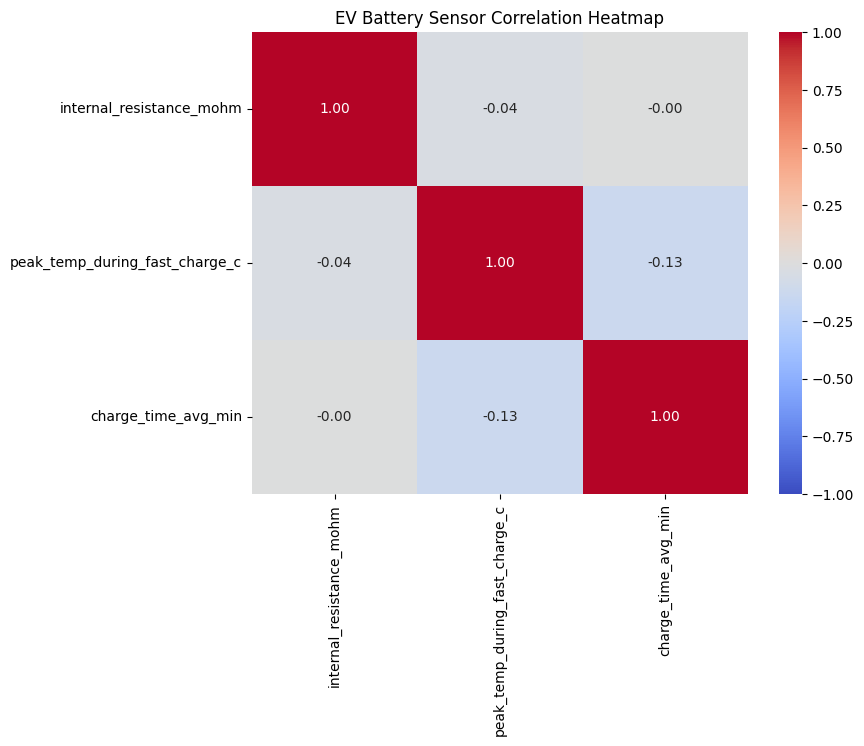

In [14]:
correlation = X_imputed[sensor_features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('EV Battery Sensor Correlation Heatmap')
plt.show()

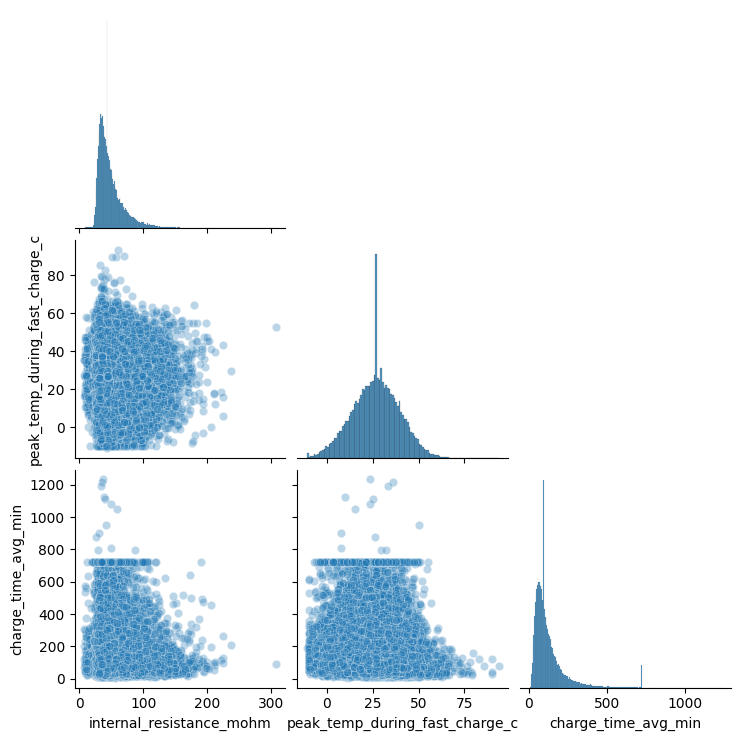

In [15]:
sns.pairplot(
    X_imputed[sensor_features],
    corner=True,
    diag_kind='hist',
    plot_kws={'alpha': 0.3}
)

plt.show()

In [16]:
for col in sensor_features:

    print(f"\nTop 10 values: {col}")

    display(
        X_imputed.nlargest(10, col)[sensor_features]
    )


Top 10 values: internal_resistance_mohm


,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
181,307.090497,53.0,88.1
12196,237.727026,29.7,206.1
6148,224.530000,5.9,125.8
37170,224.320000,15.9,94.4
36732,223.896331,43.4,261.4
29918,221.546474,18.8,114.5
4292,212.354196,12.4,81.1
5440,211.520000,39.7,101.8
35244,210.750000,18.2,52.1
31377,209.944823,17.6,94.4



Top 10 values: peak_temp_during_fast_charge_c


,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
32726,60.37,93.640098,75.1
23935,69.34,90.123121,25.9
24562,51.99,89.820236,40.4
2072,57.17,89.762688,119.6
34601,32.42,85.435943,75.4
40065,39.52,82.690736,122.9
30109,34.09,79.526255,158.1
34972,45.33,79.253609,19.6
6502,35.08,78.956761,36.4
744,40.71,78.121124,43.8



Top 10 values: charge_time_avg_min


,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
19299,37.44,23.4,1232.429212
35031,35.68,35.8,1218.957282
43877,34.69,33.4,1190.084218
7608,38.62,9.7,1121.000358
14373,40.92,25.0,1114.482740
10668,49.66,23.2,1081.529555
44255,59.78,15.1,1046.595244
21897,41.24,50.2,949.559798
4201,30.34,7.4,903.883373
170,26.37,26.1,875.794535


In [17]:
negative_temp = X_imputed[
    X_imputed['peak_temp_during_fast_charge_c'] < 0
]

print("Negative temperature observations:", len(negative_temp))

display(negative_temp.head(10))

Negative temperature observations: 979


,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
0,92.70,-1.3,40.1
14,112.44,-9.3,94.4
19,45.86,-0.5,244.1
58,94.04,-10.0,155.4
176,82.30,-0.1,327.4
324,34.20,-6.1,20.2
329,105.01,-3.4,64.8
410,36.89,-0.7,98.0
466,31.82,-1.0,234.6
482,112.30,-1.4,94.4


# **Model Development**

In [18]:
print("Total observations:", len(data))
print("Unique batteries:", data['battery_id'].nunique())

print(
    "Batteries with multiple observations:",
    data['battery_id'].duplicated().sum()
)

Total observations: 50000
Unique batteries: 2600
Batteries with multiple observations: 47400


In [19]:
from sklearn.model_selection import GroupShuffleSplit

# Keep rows with at least one available sensor reading
model_data = data.dropna(
    subset=sensor_features,
    how='all'
).copy()

# Split by battery_id to prevent battery-level data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        model_data,
        groups=model_data['battery_id']
    )
)

train_data = model_data.iloc[train_idx]
test_data = model_data.iloc[test_idx]

print("Training observations:", len(train_data))
print("Testing observations:", len(test_data))

print(
    "Common battery IDs:",
    len(set(train_data['battery_id']) &
        set(test_data['battery_id']))
)

Training observations: 39863
Testing observations: 10134
Common battery IDs: 0


In [20]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

X_train = train_data[sensor_features]
X_test = test_data[sensor_features]

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (39863, 3)
Testing shape: (10134, 3)


**Train Isolation Forest**

In [21]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

model.fit(X_train_scaled)

print("Isolation Forest trained successfully!")

Isolation Forest trained successfully!


In [22]:
predictions = model.predict(X_test_scaled)

print("First 20 predictions:")
print(predictions[:20])

First 20 predictions:
[ 1  1  1  1  1 -1  1  1  1 -1  1  1  1  1  1  1  1  1  1  1]


In [23]:
test_results = test_data.copy()

test_results['anomaly_prediction'] = predictions

test_results['anomaly_status'] = (
    test_results['anomaly_prediction'].map({
        1: 'Normal',
        -1: 'Anomaly'
    })
)

display(test_results.head(10))

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category,anomaly_prediction,anomaly_status
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal,1,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal,1,Normal
5,BATT_02221,OBS_042725,NCA,NexCell,Sedan-E1,68.5,2023-08-05,2025-01-20,534.0,838.0,...,1.0,2024-08-14,BMS_v3.0,0.0,89.54,691,Low,Normal,1,Normal
6,BATT_00566,OBS_010823,LFP,GigaWatt Labs,SUV-E5,65.8,2025-08-31,2025-11-04,65.0,36.0,...,1.0,2025-10-29,BMS_v2.3,0.0,99.92,4432,Low,Normal,1,Normal
9,BATT_01923,OBS_036959,LMO,NaN,Hatch-E3,49.1,2022-01-23,2025-07-10,1264.0,702.0,...,5.0,2024-11-30,BMS_v2.3,0.0,83.97,166,Medium,Normal,1,Normal
12,BATT_00325,OBS_006189,NMC,IonFlux,Compact-E1,66.1,2023-04-10,2023-04-18,8.0,11.0,...,NaN,NaN,BMS_v3.0,0.0,99.17,1328,Low,Normal,-1,Anomaly
13,BATT_00074,OBS_001415,NMC,NaN,Van-E4,70.4,2024-01-28,2025-12-21,693.0,512.0,...,3.0,2025-07-20,BMS_v3.2,0.0,91.30,829,Low,Normal,1,Normal
16,BATT_00791,OBS_015178,LMO,NaN,Hatch-E3,NaN,2021-12-15,2025-01-05,1117.0,682.0,...,3.0,2024-05-05,BMS_v3.2,0.0,87.30,127,Low,Normal,1,Normal
18,BATT_00658,OBS_012610,LFP,PowerGrid Batteries,NaN,71.7,2023-03-16,NaN,982.0,696.0,...,4.0,2025-05-29,BMS_v2.1,0.0,95.14,2853,Low,Normal,1,Normal
21,BATT_00830,OBS_015909,LFP,VoltaCore,Crossover-X2,61.0,2025-02-09,2025-07-12,153.0,59.0,...,1.0,2025-04-27,BMS_v3.0,0.0,99.40,3779,Low,Normal,-1,Anomaly


In [24]:
print("Anomaly distribution:")

print(test_results['anomaly_status'].value_counts())

anomaly_percentage = (
    test_results['anomaly_prediction'] == -1
).mean() * 100

normal_percentage = (
    test_results['anomaly_prediction'] == 1
).mean() * 100

print(f"\nNormal: {normal_percentage:.2f}%")
print(f"Anomalies: {anomaly_percentage:.2f}%")

Anomaly distribution:
anomaly_status
Normal     9627
Anomaly     507
Name: count, dtype: int64

Normal: 95.00%
Anomalies: 5.00%


In [25]:
test_results['anomaly_score'] = (
    -model.score_samples(X_test_scaled)
)

top_anomalies = test_results.sort_values(
    by='anomaly_score',
    ascending=False
)

display(
    top_anomalies[
        [
            'battery_id',
            'internal_resistance_mohm',
            'peak_temp_during_fast_charge_c',
            'charge_time_avg_min',
            'anomaly_score',
            'anomaly_status'
        ]
    ].head(20)
)

,battery_id,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min,anomaly_score,anomaly_status
5827,BATT_01757,205.640000,0.200000,454.400000,0.744891,Anomaly
23986,BATT_02078,67.650000,-5.800000,720.000000,0.734947,Anomaly
26492,BATT_01757,193.880000,14.600000,476.900000,0.731472,Anomaly
26280,BATT_02070,117.630000,25.200000,720.000000,0.727374,Anomaly
31791,BATT_01564,106.570000,35.200000,720.000000,0.722603,Anomaly
24650,BATT_00903,119.830000,21.000000,596.900000,0.719357,Anomaly
17509,BATT_00903,107.120000,16.100000,720.000000,0.717083,Anomaly
11997,BATT_01969,151.175308,34.000000,469.100000,0.714097,Anomaly
31936,BATT_00680,100.320000,32.000000,720.000000,0.712026,Anomaly
45675,BATT_00963,98.800000,13.700000,720.000000,0.711971,Anomaly


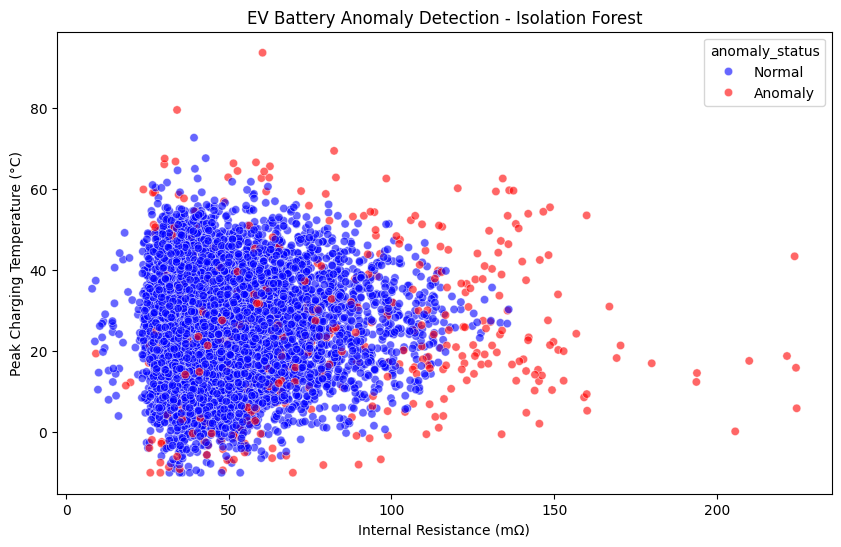

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=test_results,
    x='internal_resistance_mohm',
    y='peak_temp_during_fast_charge_c',
    hue='anomaly_status',
    palette={
        'Normal': 'blue',
        'Anomaly': 'red'
    },
    alpha=0.6
)

plt.title('EV Battery Anomaly Detection - Isolation Forest')
plt.xlabel('Internal Resistance (mΩ)')
plt.ylabel('Peak Charging Temperature (°C)')

plt.show()

In [27]:
display(
    test_results.groupby('anomaly_status')[
        sensor_features
    ].mean().round(2)
)

,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min
anomaly_status,,,
Anomaly,76.04,25.19,414.49
Normal,47.52,25.93,116.89


Local Outlier Factor **Model**

In [28]:
from sklearn.neighbors import LocalOutlierFactor

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    novelty=True
)

lof_model.fit(X_train_scaled)

print("LOF model trained successfully!")

LOF model trained successfully!


In [29]:
lof_predictions = lof_model.predict(X_test_scaled)

print("First 20 predictions:")
print(lof_predictions[:20])

First 20 predictions:
[ 1  1  1 -1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1 -1]


In [30]:
test_results['lof_prediction'] = lof_predictions

test_results['lof_status'] = (
    test_results['lof_prediction'].map({
        1: 'Normal',
        -1: 'Anomaly'
    })
)

display(test_results.head(10))

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category,anomaly_prediction,anomaly_status,anomaly_score,lof_prediction,lof_status
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,0.0,99.18,1375,Low,Normal,1,Normal,0.450785,1,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,0.0,91.86,715,Low,Normal,1,Normal,0.428136,1,Normal
5,BATT_02221,OBS_042725,NCA,NexCell,Sedan-E1,68.5,2023-08-05,2025-01-20,534.0,838.0,...,0.0,89.54,691,Low,Normal,1,Normal,0.450930,1,Normal
6,BATT_00566,OBS_010823,LFP,GigaWatt Labs,SUV-E5,65.8,2025-08-31,2025-11-04,65.0,36.0,...,0.0,99.92,4432,Low,Normal,1,Normal,0.494379,-1,Anomaly
9,BATT_01923,OBS_036959,LMO,NaN,Hatch-E3,49.1,2022-01-23,2025-07-10,1264.0,702.0,...,0.0,83.97,166,Medium,Normal,1,Normal,0.477785,1,Normal
12,BATT_00325,OBS_006189,NMC,IonFlux,Compact-E1,66.1,2023-04-10,2023-04-18,8.0,11.0,...,0.0,99.17,1328,Low,Normal,-1,Anomaly,0.599412,1,Normal
13,BATT_00074,OBS_001415,NMC,NaN,Van-E4,70.4,2024-01-28,2025-12-21,693.0,512.0,...,0.0,91.30,829,Low,Normal,1,Normal,0.410861,1,Normal
16,BATT_00791,OBS_015178,LMO,NaN,Hatch-E3,NaN,2021-12-15,2025-01-05,1117.0,682.0,...,0.0,87.30,127,Low,Normal,1,Normal,0.391968,1,Normal
18,BATT_00658,OBS_012610,LFP,PowerGrid Batteries,NaN,71.7,2023-03-16,NaN,982.0,696.0,...,0.0,95.14,2853,Low,Normal,1,Normal,0.378301,1,Normal
21,BATT_00830,OBS_015909,LFP,VoltaCore,Crossover-X2,61.0,2025-02-09,2025-07-12,153.0,59.0,...,0.0,99.40,3779,Low,Normal,-1,Anomaly,0.679441,-1,Anomaly


In [31]:
print("LOF anomaly distribution:")

print(test_results['lof_status'].value_counts())

lof_anomaly_percentage = (
    test_results['lof_prediction'] == -1
).mean() * 100

lof_normal_percentage = (
    test_results['lof_prediction'] == 1
).mean() * 100

print(f"\nNormal: {lof_normal_percentage:.2f}%")
print(f"Anomalies: {lof_anomaly_percentage:.2f}%")

LOF anomaly distribution:
lof_status
Normal     9586
Anomaly     548
Name: count, dtype: int64

Normal: 94.59%
Anomalies: 5.41%


In [32]:
test_results['lof_score'] = (
    -lof_model.score_samples(X_test_scaled)
)

lof_top_anomalies = test_results.sort_values(
    by='lof_score',
    ascending=False
)

display(
    lof_top_anomalies[
        [
            'battery_id',
            'internal_resistance_mohm',
            'peak_temp_during_fast_charge_c',
            'charge_time_avg_min',
            'lof_score',
            'lof_status'
        ]
    ].head(20)
)

,battery_id,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min,lof_score,lof_status
35031,BATT_00650,35.680000,35.800000,1218.957282,8.217451,Anomaly
10668,BATT_00325,49.660000,23.200000,1081.529555,6.825885,Anomaly
7608,BATT_00150,38.620000,9.700000,1121.000358,6.145652,Anomaly
170,BATT_02216,26.370000,26.100000,875.794535,5.710730,Anomaly
18744,BATT_01129,7.992252,35.400000,308.400000,2.170056,Anomaly
5827,BATT_01757,205.640000,0.200000,454.400000,2.125736,Anomaly
23356,BATT_00496,16.097818,4.000000,176.100000,2.124128,Anomaly
3532,BATT_00150,9.153784,19.400000,534.400000,2.059712,Anomaly
4989,BATT_02288,10.005311,14.700000,265.000000,2.002775,Anomaly
40944,BATT_00522,15.350784,9.000000,243.400000,1.998500,Anomaly


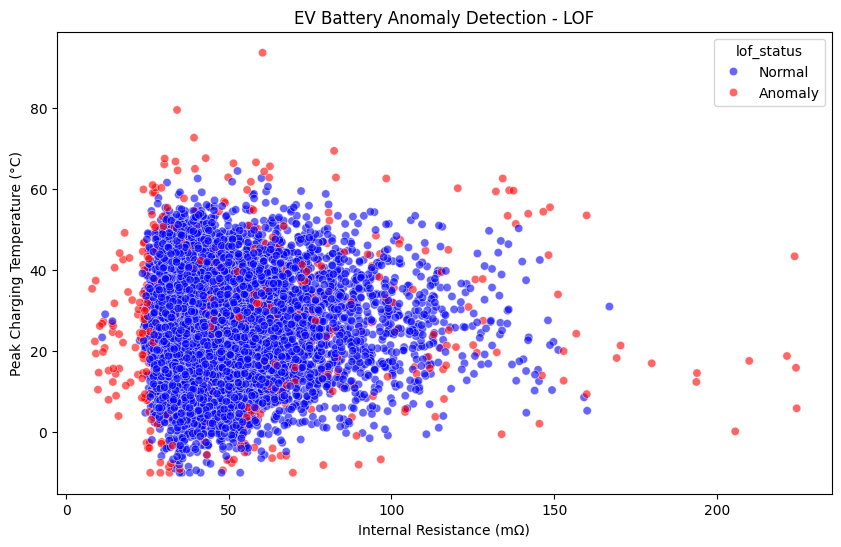

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=test_results,
    x='internal_resistance_mohm',
    y='peak_temp_during_fast_charge_c',
    hue='lof_status',
    palette={
        'Normal': 'blue',
        'Anomaly': 'red'
    },
    alpha=0.6
)

plt.title('EV Battery Anomaly Detection - LOF')
plt.xlabel('Internal Resistance (mΩ)')
plt.ylabel('Peak Charging Temperature (°C)')

plt.show()

# **Comparison of models**

In [34]:
print("Isolation Forest Anomalies:",
      (test_results['anomaly_prediction'] == -1).sum())

print("LOF Anomalies:",
      (test_results['lof_prediction'] == -1).sum())

Isolation Forest Anomalies: 507
LOF Anomalies: 548


In [35]:
agreement = (
    test_results['anomaly_prediction'] ==
    test_results['lof_prediction']
).mean() * 100

print(f"Model Agreement: {agreement:.2f}%")

Model Agreement: 93.83%


In [36]:
comparison = pd.DataFrame({
    'Model': ['Isolation Forest', 'LOF'],
    'Total Anomalies': [
        (test_results['anomaly_prediction'] == -1).sum(),
        (test_results['lof_prediction'] == -1).sum()
    ],
    'Anomaly Percentage': [
        (test_results['anomaly_prediction'] == -1).mean() * 100,
        (test_results['lof_prediction'] == -1).mean() * 100
    ]
})

display(comparison.round(2))

,Model,Total Anomalies,Anomaly Percentage
0,Isolation Forest,507,5.00
1,LOF,548,5.41


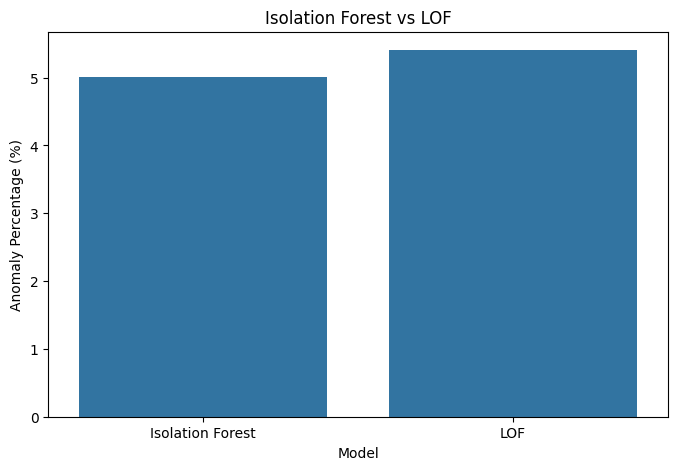

In [37]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x='Model',
    y='Anomaly Percentage'
)

plt.title('Isolation Forest vs LOF')
plt.ylabel('Anomaly Percentage (%)')

plt.show()

In [38]:
common_anomalies = test_results[
    (test_results['anomaly_prediction'] == -1) &
    (test_results['lof_prediction'] == -1)
]

print("Common anomalies:", len(common_anomalies))

display(
    common_anomalies[
        [
            'battery_id',
            'internal_resistance_mohm',
            'peak_temp_during_fast_charge_c',
            'charge_time_avg_min',
            'anomaly_score',
            'lof_score'
        ]
    ].head(20)
)

Common anomalies: 215


,battery_id,internal_resistance_mohm,peak_temp_during_fast_charge_c,charge_time_avg_min,anomaly_score,lof_score
21,BATT_00830,28.830000,10.000000,720.000000,0.679441,1.208092
170,BATT_02216,26.370000,26.100000,875.794535,0.672508,5.710730
320,BATT_00411,110.455294,44.800000,9.300000,0.616140,1.179319
470,BATT_00903,104.170000,5.000000,481.400000,0.688858,1.140879
562,BATT_01897,84.950000,11.100000,459.500000,0.648667,1.134999
849,BATT_01561,48.440000,43.000000,604.900000,0.643613,1.212027
1520,BATT_00681,75.370000,5.600000,578.000000,0.685999,1.159610
1680,BATT_00904,50.920000,12.700000,613.200000,0.642797,1.142881
1846,BATT_02473,96.490000,44.000000,477.300000,0.672767,1.140622
2048,BATT_02034,30.160000,66.102364,144.500000,0.593615,1.472360
